## 1. Import libraries and select GPU


In [1]:
import os
import sys
import glob
import shutil
import zipfile
import subprocess
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, accuracy_score
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

Using device: cuda


## 2. Find and extract the uploaded dataset



In [2]:
# Search Kaggle input for the uploaded ZIP or an already-extracted dataset.
SEARCH_ROOTS = ["/kaggle/input", "/kaggle/working"]
zip_candidates = []
yaml_candidates = []

for root in SEARCH_ROOTS:
    if os.path.exists(root):
        for current, dirs, files in os.walk(root):
            dirs[:] = [d for d in dirs if d not in [".ipynb_checkpoints"]]
            for filename in files:
                full_path = os.path.join(current, filename)
                if filename.lower().endswith(".zip"):
                    zip_candidates.append(full_path)
                elif filename.lower() == "data.yaml":
                    yaml_candidates.append(full_path)

WORK_DIR = "/kaggle/working/bioluminescence_data"
os.makedirs(WORK_DIR, exist_ok=True)

# Extract the outer ZIP (if found).
if zip_candidates:
    print("ZIP files found:")
    for p in zip_candidates:
        print(" -", p)

    # Use the first matching ZIP. If multiple ZIPs are attached, verify this path.
    OUTER_ZIP = zip_candidates[0]
    print("\nExtracting:", OUTER_ZIP)
    with zipfile.ZipFile(OUTER_ZIP, "r") as zf:
        zf.extractall(WORK_DIR)
else:
    print("No ZIP found. Checking whether data.yaml is already available.")

# Locate nested RAR archives.
rar_candidates = glob.glob(os.path.join(WORK_DIR, "**", "*.rar"), recursive=True)
print("Nested RAR files:", rar_candidates)

if rar_candidates:
    rar_path = rar_candidates[0]
    rar_output = os.path.join(WORK_DIR, "rar_extracted")
    os.makedirs(rar_output, exist_ok=True)

    # Find an already installed extractor.
    extractor = (
        shutil.which("unar") or
        shutil.which("7z") or
        shutil.which("7zz") or
        shutil.which("unrar")
    )

    # Try installing 'unar' if no extractor is present.
    if extractor is None:
        print("No RAR extractor found. Trying to install unar...")
        try:
            subprocess.run(["apt-get", "update", "-qq"], check=True)
            subprocess.run(["apt-get", "install", "-y", "-qq", "unar"], check=True)
            extractor = shutil.which("unar")
        except Exception as e:
            print("Automatic installation failed:", e)

    if extractor is None:
        raise RuntimeError(
            "Could not find a RAR extractor. Extract the inner .rar file on your computer, "
            "then upload the extracted BT3.8k folder to Kaggle as a Dataset."
        )

    print("Using extractor:", extractor)
    if os.path.basename(extractor) == "unar":
        cmd = [extractor, "-o", rar_output, "-f", rar_path]
    elif os.path.basename(extractor) in ["7z", "7zz"]:
        cmd = [extractor, "x", "-y", f"-o{rar_output}", rar_path]
    else:
        cmd = [extractor, "x", "-o+", rar_path, rar_output + "/"]

    result = subprocess.run(cmd, capture_output=True, text=True)
    print(result.stdout[-2000:])
    if result.returncode != 0:
        print(result.stderr[-2000:])
        raise RuntimeError("RAR extraction failed. See the error above.")

# Locate data.yaml after extraction or from the original Kaggle input.
yaml_candidates = []
for root in SEARCH_ROOTS:
    if os.path.exists(root):
        for current, dirs, files in os.walk(root):
            dirs[:] = [d for d in dirs if d not in [".ipynb_checkpoints"]]
            if "data.yaml" in files:
                yaml_candidates.append(os.path.join(current, "data.yaml"))

if not yaml_candidates:
    raise FileNotFoundError(
        "data.yaml was not found. Check that the outer ZIP and inner RAR were extracted."
    )

DATA_ROOT = os.path.dirname(yaml_candidates[-1])
print("Dataset root:", DATA_ROOT)
print("Top-level contents:", os.listdir(DATA_ROOT))

No ZIP found. Checking whether data.yaml is already available.
Nested RAR files: []
Dataset root: /kaggle/input/datasets/nusratraina/biolumin/BT3.8k A Benchmark Dataset for Monitoring Biolumin/BT3.8k/BT3.8k
Top-level contents: ['data.yaml', 'test', 'train', 'val']


## 3. Read class names and inspect the train/valid/test folders

The dataset's `data.yaml` file defines the class names. The code below supports class names stored as either a list or a dictionary.

In [3]:

# Read data.yaml
import os
import yaml
import glob

yaml_path = os.path.join(DATA_ROOT, "data.yaml")

with open(yaml_path, "r") as f:
    data_config = yaml.safe_load(f)

print("data.yaml content:", data_config)

# Original dataset has only one object class
object_class_name = data_config["names"][0]

# Convert the single YOLO class into binary classification
class_names = ["background", object_class_name]
num_classes = 2

print("CNN Classes:", class_names)
print("Number of classes:", num_classes)

# Find dataset split folders
def find_split_folder(split_name):
    possible_paths = [
        os.path.join(DATA_ROOT, split_name),
        os.path.join(DATA_ROOT, split_name, "images")
    ]

    for path in possible_paths:
        if os.path.isdir(path):
            return path

    return None


train_folder = find_split_folder("train")
test_folder = find_split_folder("test")

# Validation may be named valid or val
valid_folder = (
    find_split_folder("valid")
    or find_split_folder("val")
)

SPLIT_DIRS = {
    "train": train_folder,
    "test": test_folder
}

if valid_folder:
    SPLIT_DIRS["valid"] = valid_folder

print("\nAvailable folders:")
for split, folder in SPLIT_DIRS.items():
    print(split, ":", folder)

if train_folder is None or test_folder is None:
    raise FileNotFoundError("Train or Test folder not found!")

if valid_folder is None:
    print("\nValidation folder not found.")
    print("We will create validation data from the training dataset.")





data.yaml content: {'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 1, 'names': ['blue_tear']}
CNN Classes: ['background', 'blue_tear']
Number of classes: 2

Available folders:
train : /kaggle/input/datasets/nusratraina/biolumin/BT3.8k A Benchmark Dataset for Monitoring Biolumin/BT3.8k/BT3.8k/train
test : /kaggle/input/datasets/nusratraina/biolumin/BT3.8k A Benchmark Dataset for Monitoring Biolumin/BT3.8k/BT3.8k/test
valid : /kaggle/input/datasets/nusratraina/biolumin/BT3.8k A Benchmark Dataset for Monitoring Biolumin/BT3.8k/BT3.8k/val


## 4. Convert YOLO annotations into image-level class labels

A YOLO annotation line usually looks like:

`class_id x_center y_center width height`

For a basic image-classification CNN, we use the most frequent class ID in each image's annotation file as that image's label. Empty annotation files are ignored.

In [4]:

from collections import Counter
from sklearn.model_selection import train_test_split

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def read_yolo_image_label(txt_path):

    # Missing annotation: skip this image
    if not os.path.isfile(txt_path):
        return None

    class_ids = []

    with open(txt_path, "r") as f:
        for line in f:
            parts = line.strip().split()

            if parts:
                try:
                    class_ids.append(int(float(parts[0])))
                except ValueError:
                    continue

    # Empty annotation = background (class 0)
    if len(class_ids) == 0:
        return 0

    # YOLO object detected = blue_tear (class 1)
    return 1


def build_image_records(split_folder):

    records = []
    skipped = 0
    background_count = 0
    object_count = 0

    for current, _, files in os.walk(split_folder):

        for filename in files:

            ext = os.path.splitext(filename)[1].lower()

            if ext not in IMAGE_EXTENSIONS:
                continue

            image_path = os.path.join(current, filename)
            txt_path = os.path.splitext(image_path)[0] + ".txt"

            label = read_yolo_image_label(txt_path)

            if label is None:
                skipped += 1
                continue

            records.append((image_path, label))

            if label == 0:
                background_count += 1
            else:
                object_count += 1

    return records, skipped, background_count, object_count


# Load training and test data
train_records, train_skipped, train_bg, train_obj = (
    build_image_records(SPLIT_DIRS["train"])
)

test_records, test_skipped, test_bg, test_obj = (
    build_image_records(SPLIT_DIRS["test"])
)

print("Training images:", len(train_records))
print("Training background:", train_bg)
print("Training blue_tear:", train_obj)

print("\nTesting images:", len(test_records))
print("Testing background:", test_bg)
print("Testing blue_tear:", test_obj)

print("\nSkipped training images:", train_skipped)
print("Skipped testing images:", test_skipped)


# Create validation split if no validation folder exists
if "valid" in SPLIT_DIRS:

    val_records, val_skipped, val_bg, val_obj = (
        build_image_records(SPLIT_DIRS["valid"])
    )

    print("\nUsing existing validation folder.")

else:

    labels = [label for _, label in train_records]

    if len(set(labels)) < 2:
        raise ValueError(
            "Training data contains only one class. "
            "Empty YOLO annotation files are required "
            "to create background samples."
        )

    train_records, val_records = train_test_split(
        train_records,
        test_size=0.20,
        random_state=42,
        stratify=labels
    )

    print("\nCreated 80:20 train-validation split.")

# Final class distribution
records_by_split = {
    "train": train_records,
    "valid": val_records,
    "test": test_records
}

for split, records in records_by_split.items():

    counts = Counter(label for _, label in records)

    print(f"\n{split.upper()} DISTRIBUTION")
    print("Background:", counts.get(0, 0))
    print("Blue tear:", counts.get(1, 0))
    print("Total:", len(records))

# Check if both classes exist in training
training_classes = set(label for _, label in train_records)

if len(training_classes) < 2:
    raise ValueError(
        "Both classes are not available in training data. "
        "Please check the empty YOLO annotation files."
    )

print("\nDataset preparation completed successfully!")
print("Classes:", class_names)
print("Number of classes:", num_classes)


   

    
   

Training images: 2674
Training background: 25
Training blue_tear: 2649

Testing images: 378
Testing background: 1
Testing blue_tear: 377

Skipped training images: 6
Skipped testing images: 4

Using existing validation folder.

TRAIN DISTRIBUTION
Background: 25
Blue tear: 2649
Total: 2674

VALID DISTRIBUTION
Background: 0
Blue tear: 764
Total: 764

TEST DISTRIBUTION
Background: 1
Blue tear: 377
Total: 378

Dataset preparation completed successfully!
Classes: ['background', 'blue_tear']
Number of classes: 2


## 5. Check class distribution

A class imbalance can affect accuracy. This table and bar chart show how many labelled images belong to each class in each split.

,split,class_id,class_name,image_count
0,train,0,background,25
1,train,1,blue_tear,2649
2,valid,0,background,0
3,valid,1,blue_tear,764
4,test,0,background,1
5,test,1,blue_tear,377


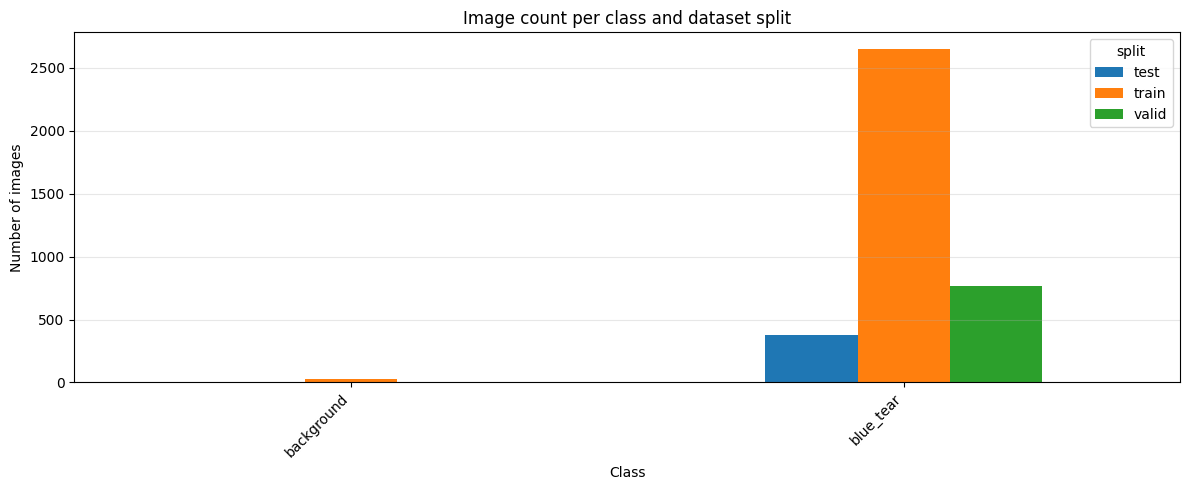

In [5]:
distribution_rows = []
for split, records in records_by_split.items():
    counts = Counter(label for _, label in records)
    for class_id, class_name in enumerate(class_names):
        distribution_rows.append({
            "split": split,
            "class_id": class_id,
            "class_name": class_name,
            "image_count": counts.get(class_id, 0)
        })

distribution_df = pd.DataFrame(distribution_rows)
display(distribution_df)

pivot_df = distribution_df.pivot(
    index="class_name", columns="split", values="image_count"
).fillna(0)

pivot_df.plot(kind="bar", figsize=(12, 5))
plt.title("Image count per class and dataset split")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Create PyTorch Dataset and DataLoaders

All images are resized to `128 × 128` and converted to tensors. Training images receive light augmentation; validation and test images remain unchanged.

In [6]:
IMG_SIZE = 128
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor()
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

class BioluminescenceDataset(Dataset):
    def __init__(self, records, transform=None):
        self.records = records
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        image_path, label = self.records[index]
        image = Image.open(image_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, int(label)


train_ds = BioluminescenceDataset(records_by_split["train"], train_transform)
val_ds = BioluminescenceDataset(records_by_split["valid"], eval_transform)
test_ds = BioluminescenceDataset(records_by_split["test"], eval_transform)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True
)

print("Train images:", len(train_ds))
print("Validation images:", len(val_ds))
print("Test images:", len(test_ds))

Train images: 2674
Validation images: 764
Test images: 378


### View a few training images

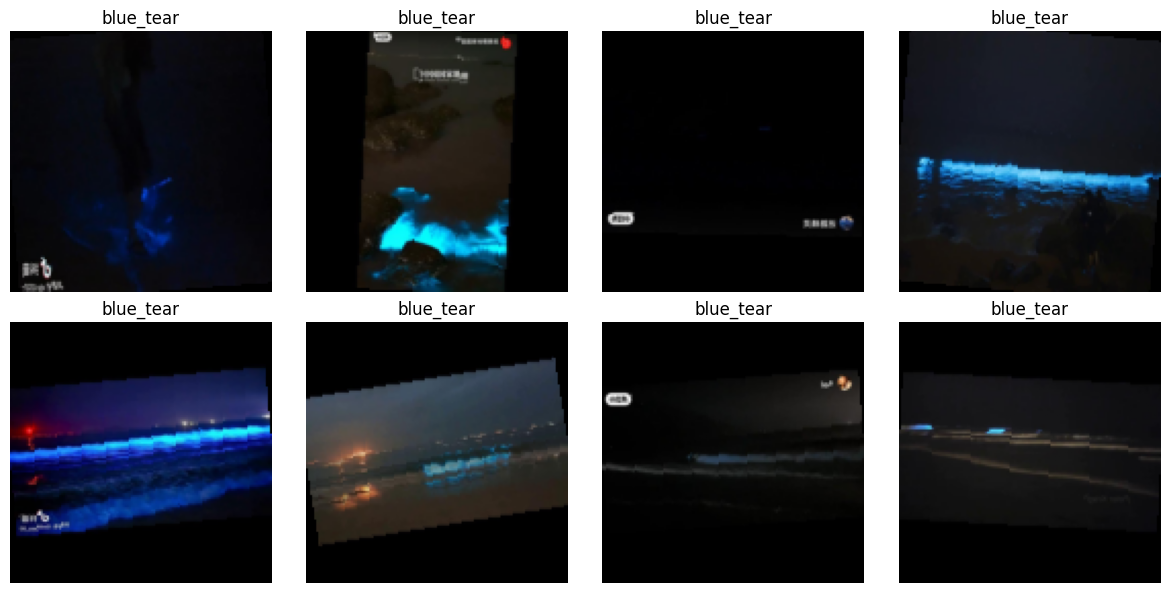

In [7]:
images, labels = next(iter(train_loader))

plt.figure(figsize=(12, 6))
for i in range(min(8, len(images))):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].permute(1, 2, 0))
    plt.title(class_names[int(labels[i])])
    plt.axis("off")
plt.tight_layout()
plt.show()

## 7. Build a basic CNN from scratch

This CNN has three convolution blocks:

- `Conv2d` learns image patterns.
- `ReLU` adds non-linearity.
- `MaxPool2d` reduces image feature-map size.
- `AdaptiveAvgPool2d` produces a compact feature representation.
- `Linear` layers perform the final classification.

No pretrained model or transfer learning is used.

In [8]:
class BasicCNN(nn.Module):
    def __init__(self, num_classes):
        super(BasicCNN, self).__init__()

        # Feature extraction block 1
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Feature extraction block 2
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)

        # Feature extraction block 3
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        # Reduce each feature map to 1 x 1
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        # Classification head
        self.dropout = nn.Dropout(0.4)
        self.fc1 = nn.Linear(64, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))

        x = self.global_pool(x)
        x = torch.flatten(x, 1)

        x = self.dropout(x)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)  # raw class scores (logits)
        return x


model = BasicCNN(num_classes=num_classes).to(device)
print(model)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {total_params:,}")

BasicCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (global_pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (dropout): Dropout(p=0.4, inplace=False)
  (fc1): Linear(in_features=64, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=2, bias=True)
)
Trainable parameters: 32,162


## 8. Train the CNN

We use:
- **Loss:** CrossEntropyLoss
- **Optimizer:** Adam
- **Learning rate:** 0.001
- **Epochs:** 15 (you can increase this if training time allows)

The model learns only from the training split. Validation data is used to monitor performance after each epoch.

In [9]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

def run_one_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            if training:
                optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                optimizer.step()

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += batch_size

    return total_loss / max(total, 1), correct / max(total, 1)


EPOCHS = 15
history = {
    "train_loss": [], "val_loss": [],
    "train_acc": [], "val_acc": []
}

best_val_loss = float("inf")
best_model_path = "/kaggle/working/best_basic_cnn.pth"

for epoch in range(EPOCHS):
    train_loss, train_acc = run_one_epoch(
        model, train_loader, criterion, optimizer
    )
    val_loss, val_acc = run_one_epoch(
        model, val_loader, criterion, optimizer=None
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), best_model_path)

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} "
        f"|| Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}"
    )

print("\nBest model saved to:", best_model_path)

Epoch [01/15] Train Loss: 0.1458 | Train Acc: 0.9783 || Val Loss: 0.0092 | Val Acc: 1.0000
Epoch [02/15] Train Loss: 0.0518 | Train Acc: 0.9907 || Val Loss: 0.0094 | Val Acc: 1.0000
Epoch [03/15] Train Loss: 0.0507 | Train Acc: 0.9907 || Val Loss: 0.0005 | Val Acc: 1.0000
Epoch [04/15] Train Loss: 0.0522 | Train Acc: 0.9907 || Val Loss: 0.0035 | Val Acc: 1.0000
Epoch [05/15] Train Loss: 0.0477 | Train Acc: 0.9907 || Val Loss: 0.0049 | Val Acc: 1.0000
Epoch [06/15] Train Loss: 0.0444 | Train Acc: 0.9907 || Val Loss: 0.0098 | Val Acc: 1.0000
Epoch [07/15] Train Loss: 0.0438 | Train Acc: 0.9907 || Val Loss: 0.0063 | Val Acc: 1.0000
Epoch [08/15] Train Loss: 0.0419 | Train Acc: 0.9907 || Val Loss: 0.0014 | Val Acc: 1.0000
Epoch [09/15] Train Loss: 0.0429 | Train Acc: 0.9907 || Val Loss: 0.0040 | Val Acc: 1.0000
Epoch [10/15] Train Loss: 0.0441 | Train Acc: 0.9907 || Val Loss: 0.0101 | Val Acc: 1.0000
Epoch [11/15] Train Loss: 0.0421 | Train Acc: 0.9907 || Val Loss: 0.0046 | Val Acc: 1.0000

## 9. Plot training and validation loss/accuracy

**How to interpret the plots:**
- Lower loss is better.
- Higher accuracy is better.
- If training accuracy improves but validation accuracy stays low, the model may be overfitting.
- If both training and validation accuracy are low, the model may be underfitting or the classes may be difficult to distinguish.

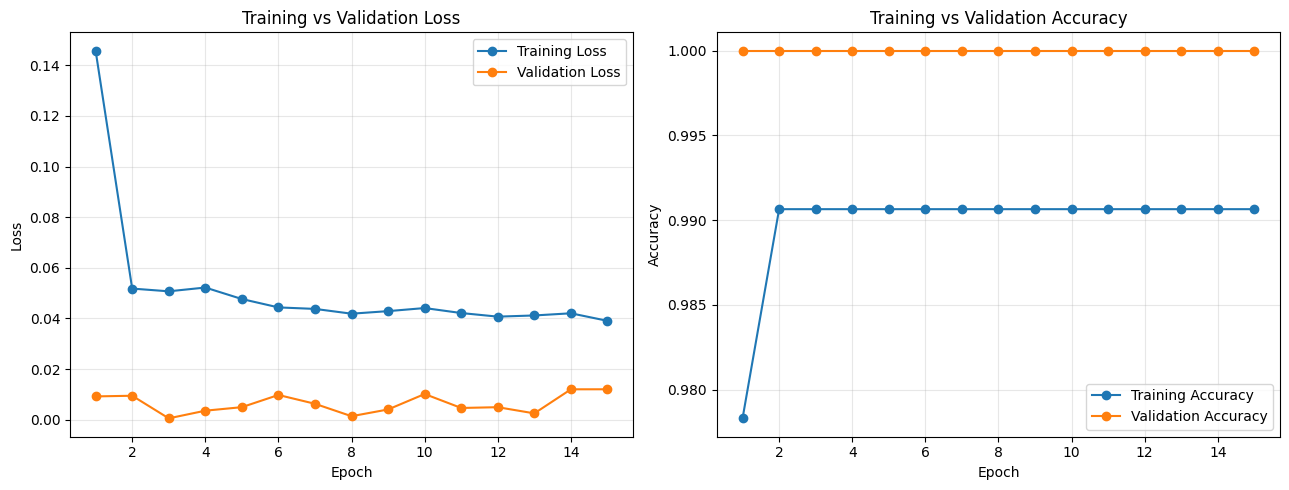

In [10]:
epochs_range = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history["train_loss"], marker="o", label="Training Loss")
plt.plot(epochs_range, history["val_loss"], marker="o", label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history["train_acc"], marker="o", label="Training Accuracy")
plt.plot(epochs_range, history["val_acc"], marker="o", label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Evaluate the best model on the test set

The test split is used only for final evaluation. We report accuracy, precision, recall, F1-score and a confusion matrix.

Test Accuracy: 0.9974 (99.74%)

Classification Report:
              precision    recall  f1-score   support

  background       0.00      0.00      0.00         1
   blue_tear       1.00      1.00      1.00       377

    accuracy                           1.00       378
   macro avg       0.50      0.50      0.50       378
weighted avg       0.99      1.00      1.00       378



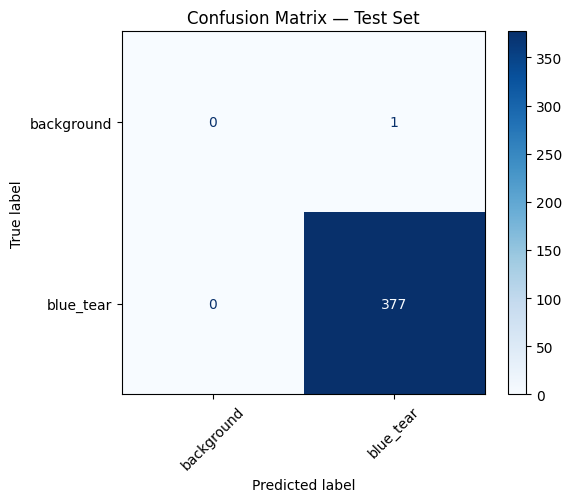

In [11]:
# Load the checkpoint with the lowest validation loss.
model.load_state_dict(torch.load(best_model_path, map_location=device))
model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        y_pred.extend(predictions.tolist())
        y_true.extend(labels.numpy().tolist())

test_accuracy = accuracy_score(y_true, y_pred)
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    labels=list(range(num_classes)),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(max(6, num_classes), max(5, num_classes)))
disp.plot(ax=ax, cmap="Blues", values_format="d", xticks_rotation=45)
plt.title("Confusion Matrix — Test Set")
plt.tight_layout()
plt.show()

## 11. Predict the class of a single image

This helper function loads one image, applies the same evaluation transform, and displays the predicted class.

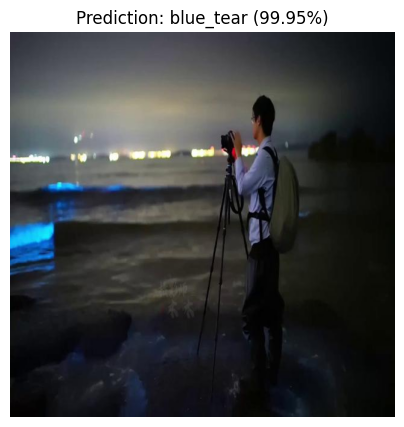

{'predicted_class': 'blue_tear', 'confidence': 0.9995342493057251}


In [12]:
def predict_single_image(image_path):
    image = Image.open(image_path).convert("RGB")
    input_tensor = eval_transform(image).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        output = model(input_tensor)
        probabilities = torch.softmax(output, dim=1)[0]
        predicted_id = int(torch.argmax(probabilities).item())

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.title(
        f"Prediction: {class_names[predicted_id]} "
        f"({probabilities[predicted_id].item()*100:.2f}%)"
    )
    plt.axis("off")
    plt.show()

    return {
        "predicted_class": class_names[predicted_id],
        "confidence": float(probabilities[predicted_id].item())
    }

# Example: predict one image from the test split.
if len(records_by_split["test"]) > 0:
    example_image_path = records_by_split["test"][0][0]
    print(predict_single_image(example_image_path))

## 12. Result analysis (use your actual notebook output)

The following cell creates a short analysis using the measured results. Do not report expected or invented accuracy; use the values printed after training.

In [13]:
best_train_acc = max(history["train_acc"])
best_val_acc = max(history["val_acc"])
final_train_acc = history["train_acc"][-1]
final_val_acc = history["val_acc"][-1]
final_train_loss = history["train_loss"][-1]
final_val_loss = history["val_loss"][-1]

print("========== RESULT ANALYSIS ==========")
print(f"Number of classes: {num_classes}")
print(f"Training images: {len(train_ds)}")
print(f"Validation images: {len(val_ds)}")
print(f"Testing images: {len(test_ds)}")
print(f"Best training accuracy: {best_train_acc*100:.2f}%")
print(f"Best validation accuracy: {best_val_acc*100:.2f}%")
print(f"Final training loss: {final_train_loss:.4f}")
print(f"Final validation loss: {final_val_loss:.4f}")
print(f"Test accuracy: {test_accuracy*100:.2f}%")

gap = final_train_acc - final_val_acc
print(f"Final train-validation accuracy gap: {gap*100:.2f} percentage points")

if gap > 0.15 and final_val_loss > final_train_loss:
    print("\nInterpretation: The model may be overfitting. Training performance is noticeably better than validation performance.")
elif best_train_acc < 0.60 and best_val_acc < 0.60:
    print("\nInterpretation: The model may be underfitting, or the visual classes may be difficult to separate.")
else:
    print("\nInterpretation: Compare the training and validation curves. A small gap suggests better generalization than a large gap.")

print("\nTest classification report:")
print(classification_report(
    y_true, y_pred,
    labels=list(range(num_classes)),
    target_names=class_names,
    zero_division=0
))

print("\nImportant limitation:")
print("This is image-level classification using the most frequent YOLO class in each image.")
print("It does not predict object locations or bounding boxes.")

========== RESULT ANALYSIS ==========
Number of classes: 2
Training images: 2674
Validation images: 764
Testing images: 378
Best training accuracy: 99.07%
Best validation accuracy: 100.00%
Final training loss: 0.0390
Final validation loss: 0.0120
Test accuracy: 99.74%
Final train-validation accuracy gap: -0.93 percentage points

Interpretation: Compare the training and validation curves. A small gap suggests better generalization than a large gap.

Test classification report:
              precision    recall  f1-score   support

  background       0.00      0.00      0.00         1
   blue_tear       1.00      1.00      1.00       377

    accuracy                           1.00       378
   macro avg       0.50      0.50      0.50       378
weighted avg       0.99      1.00      1.00       378


Important limitation:
This is image-level classification using the most frequent YOLO class in each image.
It does not predict object locations or bounding boxes.


## 13. Save the trained model

The model weights are saved in the Kaggle working directory. Download the `.pth` file from the notebook's Output/Files panel if you need it later.

In [14]:
torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "image_size": IMG_SIZE
}, "/kaggle/working/bioluminescence_basic_cnn.pth")

print("Saved: /kaggle/working/bioluminescence_basic_cnn.pth")

Saved: /kaggle/working/bioluminescence_basic_cnn.pth


In [15]:

# FINAL CNN MODEL SUMMARY

total_parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

best_train_accuracy = max(history["train_acc"]) * 100
best_val_accuracy = max(history["val_acc"]) * 100

best_train_loss = min(history["train_loss"])
best_val_loss = min(history["val_loss"])

epochs_trained = len(history["train_loss"])

print("=" * 45)
print("       CNN MODEL FINAL SUMMARY")
print("=" * 45)

print("Training Images:", len(train_ds))
print("Testing Images:", len(test_ds))

print(f"Best Training Accuracy: {best_train_accuracy:.2f}%")
print(f"Best Validation Accuracy: {best_val_accuracy:.2f}%")

print(f"Best Training Loss: {best_train_loss:.4f}")
print(f"Best Validation Loss: {best_val_loss:.4f}")

print("Number of Epochs Trained:", epochs_trained)
print("Learning Rate: 0.001")
print("Optimizer: Adam")
print("Loss Function: CrossEntropyLoss")

print("Total Trainable Parameters:", total_parameters)

print("Regularization Techniques:")
print("- Dropout (0.4)")
print("- Random Horizontal Flip")
print("- Random Rotation (10 degrees)")

print("=" * 45)
print(f"Final Test Accuracy: {test_accuracy * 100:.2f}%")
print("=" * 45)


       CNN MODEL FINAL SUMMARY
Training Images: 2674
Testing Images: 378
Best Training Accuracy: 99.07%
Best Validation Accuracy: 100.00%
Best Training Loss: 0.0390
Best Validation Loss: 0.0005
Number of Epochs Trained: 15
Learning Rate: 0.001
Optimizer: Adam
Loss Function: CrossEntropyLoss
Total Trainable Parameters: 32162
Regularization Techniques:
- Dropout (0.4)
- Random Horizontal Flip
- Random Rotation (10 degrees)
Final Test Accuracy: 99.74%
